In [1]:
import pandas as pd
import numpy as np

# carregar os dados
visits = pd.read_csv('/datasets/visits_log_us.csv')
orders = pd.read_csv('/datasets/orders_log_us.csv')
costs = pd.read_csv('/datasets/costs_us.csv')

# converter colunas de data
visits['Start Ts'] = pd.to_datetime(visits['Start Ts'])
visits['End Ts'] = pd.to_datetime(visits['End Ts'])

orders['Buy Ts'] = pd.to_datetime(orders['Buy Ts'])

costs['dt'] = pd.to_datetime(costs['dt'])

# informações gerais
print('VISITS')
print(visits.info())
print()

print('ORDERS')
print(orders.info())
print()

print('COSTS')
print(costs.info())
print()

# valores ausentes
print('Valores ausentes em visits:')
print(visits.isna().sum())
print()

print('Valores ausentes em orders:')
print(orders.isna().sum())
print()

print('Valores ausentes em costs:')
print(costs.isna().sum())
print()

# duplicados
print('Duplicados em visits:', visits.duplicated().sum())
print('Duplicados em orders:', orders.duplicated().sum())
print('Duplicados em costs:', costs.duplicated().sum())
print()

# primeiras linhas
print('VISITS')
display(visits.head())

print('ORDERS')
display(orders.head())

print('COSTS')
display(costs.head())

VISITS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   Device     359400 non-null  object        
 1   End Ts     359400 non-null  datetime64[ns]
 2   Source Id  359400 non-null  int64         
 3   Start Ts   359400 non-null  datetime64[ns]
 4   Uid        359400 non-null  uint64        
dtypes: datetime64[ns](2), int64(1), object(1), uint64(1)
memory usage: 13.7+ MB
None

ORDERS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Buy Ts   50415 non-null  datetime64[ns]
 1   Revenue  50415 non-null  float64       
 2   Uid      50415 non-null  uint64        
dtypes: datetime64[ns](1), float64(1), uint64(1)
memory usage: 1.2 MB
None

COSTS
<class 'pandas.core.frame.DataFrame'>


,Device,End Ts,Source Id,Start Ts,Uid
0,touch,2017-12-20 17:38:00,4,2017-12-20 17:20:00,16879256277535980062
1,desktop,2018-02-19 17:21:00,2,2018-02-19 16:53:00,104060357244891740
2,touch,2017-07-01 01:54:00,5,2017-07-01 01:54:00,7459035603376831527
3,desktop,2018-05-20 11:23:00,9,2018-05-20 10:59:00,16174680259334210214
4,desktop,2017-12-27 14:06:00,3,2017-12-27 14:06:00,9969694820036681168


ORDERS


,Buy Ts,Revenue,Uid
0,2017-06-01 00:10:00,17.00,10329302124590727494
1,2017-06-01 00:25:00,0.55,11627257723692907447
2,2017-06-01 00:27:00,0.37,17903680561304213844
3,2017-06-01 00:29:00,0.55,16109239769442553005
4,2017-06-01 07:58:00,0.37,14200605875248379450


COSTS


,source_id,dt,costs
0,1,2017-06-01,75.20
1,1,2017-06-02,62.25
2,1,2017-06-03,36.53
3,1,2017-06-04,55.00
4,1,2017-06-05,57.08


In [2]:
visits['session_date'] = visits['Start Ts'].dt.date
visits['session_week'] = visits['Start Ts'].dt.isocalendar().week
visits['session_month'] = visits['Start Ts'].astype('datetime64[M]')

dau_total = visits.groupby('session_date')['Uid'].nunique().mean()
wau_total = visits.groupby('session_week')['Uid'].nunique().mean()
mau_total = visits.groupby('session_month')['Uid'].nunique().mean()

print('DAU:', dau_total)
print('WAU:', wau_total)
print('MAU:', mau_total)

DAU: 907.9917582417582
WAU: 5825.288461538462
MAU: 23228.416666666668


In [3]:
sessions_per_user = (
    visits.groupby('session_date')
    .agg({'Uid': 'count'})
    .mean()
)

print(sessions_per_user)

Uid    987.362637
dtype: float64


In [4]:
visits['session_duration'] = (
    visits['End Ts'] - visits['Start Ts']
).dt.total_seconds()

print(visits['session_duration'].mean())

643.0256872565387


In [5]:
first_visit = visits.groupby('Uid')['Start Ts'].min()
visits['first_visit'] = visits['Uid'].map(first_visit)

visits['cohort_age'] = (
    visits['Start Ts'].dt.to_period('M') - visits['first_visit'].dt.to_period('M')
).apply(lambda x: x.n)

retention = visits.groupby('cohort_age')['Uid'].nunique()

print(retention)

cohort_age
0     228169
1      13815
2       8714
3       6901
4       5621
5       4616
6       3523
7       2702
8       1869
9       1315
10       900
11       596
Name: Uid, dtype: int64


In [6]:

first_order = orders.groupby('Uid')['Buy Ts'].min().reset_index()
first_visit = visits.groupby('Uid')['Start Ts'].min().reset_index()

conversion = first_order.merge(first_visit, on='Uid')

conversion['days_to_purchase'] = (
    conversion['Buy Ts'] - conversion['Start Ts']
).dt.days

print(conversion['days_to_purchase'].describe())


count    36523.000000
mean        16.729869
std         46.959088
min          0.000000
25%          0.000000
50%          0.000000
75%          2.000000
max        363.000000
Name: days_to_purchase, dtype: float64


In [7]:
orders_per_user = orders.groupby('Uid').size()

print(orders_per_user.mean())

1.3803630588943954


In [8]:
print(orders['Revenue'].mean())

4.999646930477041


In [9]:
ltv = orders.groupby('Uid')['Revenue'].sum().mean()
print(ltv)

6.901327930345262


In [10]:
first_orders = (
    orders.groupby('Uid')['Buy Ts']
    .min()
    .reset_index()
)

first_orders.columns = ['Uid', 'first_order_dt']

first_orders['first_order_month'] = (
    first_orders['first_order_dt']
    .dt.to_period('M')
)

orders['order_month'] = (
    orders['Buy Ts']
    .dt.to_period('M')
)

orders_merged = orders.merge(
    first_orders[['Uid', 'first_order_month']],
    on='Uid'
)

orders_merged['cohort_lifetime'] = (
    (orders_merged['order_month'].dt.year -
     orders_merged['first_order_month'].dt.year) * 12
    +
    (orders_merged['order_month'].dt.month -
     orders_merged['first_order_month'].dt.month)
)

In [11]:
cohorts_ltv = (
    orders_merged
    .groupby(['first_order_month', 'cohort_lifetime'])
    ['Revenue']
    .sum()
    .reset_index()
)

In [12]:
cohort_sizes = (
    first_orders
    .groupby('first_order_month')
    ['Uid']
    .nunique()
    .reset_index()
)

cohort_sizes.columns = [
    'first_order_month',
    'n_buyers'
]

In [13]:
ltv_report = cohorts_ltv.merge(
    cohort_sizes,
    on='first_order_month'
)

ltv_report['ltv'] = (
    ltv_report['Revenue']
    /
    ltv_report['n_buyers']
)

ltv_report['ltv_cum'] = (
    ltv_report
    .groupby('first_order_month')['ltv']
    .cumsum()
)

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

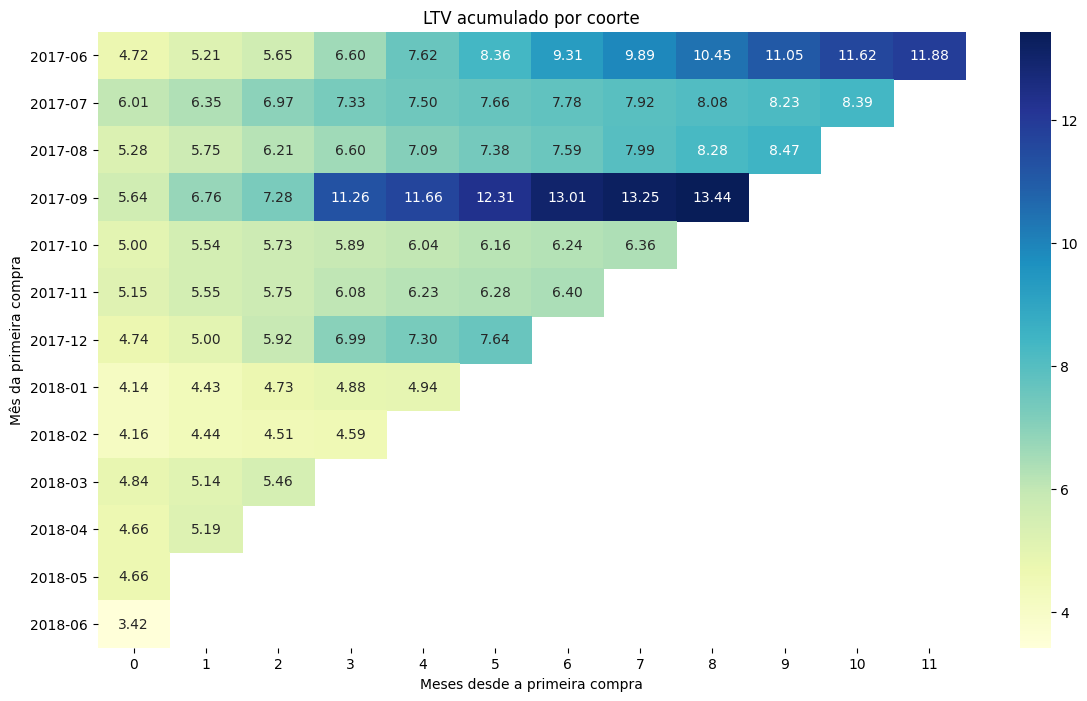

In [15]:
ltv_pivot = ltv_report.pivot_table(
    index='first_order_month',
    columns='cohort_lifetime',
    values='ltv_cum'
)

ltv_pivot.index = ltv_pivot.index.astype(str)

plt.figure(figsize=(14,8))

sns.heatmap(
    ltv_pivot,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu'
)

plt.title('LTV acumulado por coorte')
plt.xlabel('Meses desde a primeira compra')
plt.ylabel('Mês da primeira compra')

plt.show()

In [16]:
print(costs['costs'].sum())

costs_by_source = costs.groupby('source_id')['costs'].sum()
print(costs_by_source)

costs_by_date = costs.groupby('dt')['costs'].sum()
print(costs_by_date)

329131.62
source_id
1      20833.27
2      42806.04
3     141321.63
4      61073.60
5      51757.10
9       5517.49
10      5822.49
Name: costs, dtype: float64
dt
2017-06-01     735.26
2017-06-02     721.19
2017-06-03     450.85
2017-06-04     761.16
2017-06-05     821.44
               ...   
2018-05-27     532.87
2018-05-28     619.44
2018-05-29     784.79
2018-05-30    1183.00
2018-05-31    2153.70
Name: costs, Length: 364, dtype: float64


In [17]:
users_by_source = visits.groupby('Source Id')['Uid'].nunique()

cac = costs.groupby('source_id')['costs'].sum() / users_by_source
print(cac)

1     1.096546
2     1.631017
3     1.890439
4     0.731201
5     0.908434
6          NaN
7          NaN
9     0.595584
10    0.721766
dtype: float64


In [18]:
first_source = (
    visits.sort_values('Start Ts')
    .groupby('Uid')
    .first()
    .reset_index()
)

In [19]:
user_revenue = (
    orders.groupby('Uid')
    ['Revenue']
    .sum()
    .reset_index()
)

In [20]:
source_revenue = first_source.merge(
    user_revenue,
    on='Uid',
    how='left'
)

source_revenue['Revenue'] = (
    source_revenue['Revenue']
    .fillna(0)
)

In [21]:
revenue_by_source = (
    source_revenue
    .groupby('Source Id')
    ['Revenue']
    .sum()
)

In [22]:
costs_by_source = (
    costs.groupby('source_id')
    ['costs']
    .sum()
)

In [23]:
roi_by_source = (
    (revenue_by_source - costs_by_source)
    /
    costs_by_source
) * 100

print(roi_by_source)

1     49.235094
2      9.619133
3    -61.427532
4     -7.166386
5      1.674978
6           NaN
7           NaN
9      4.384421
10   -23.566550
dtype: float64


In [24]:
report = pd.DataFrame({
    'Revenue': revenue_by_source,
    'Costs': costs_by_source,
    'Users': users_by_source
})

report['CAC'] = (
    report['Costs']
    /
    report['Users']
)

report['ROI (%)'] = (
    (report['Revenue'] - report['Costs'])
    /
    report['Costs']
) * 100

print(report)

     Revenue      Costs  Users       CAC    ROI (%)
1   31090.55   20833.27  18999  1.096546  49.235094
2   46923.61   42806.04  26245  1.631017   9.619133
3   54511.24  141321.63  74756  1.890439 -61.427532
4   56696.83   61073.60  83525  0.731201  -7.166386
5   52624.02   51757.10  56974  0.908434   1.674978
6       0.00        NaN      6       NaN        NaN
7       1.22        NaN     34       NaN        NaN
9    5759.40    5517.49   9264  0.595584   4.384421
10   4450.33    5822.49   8067  0.721766 -23.566550


<AxesSubplot:xlabel='dt'>

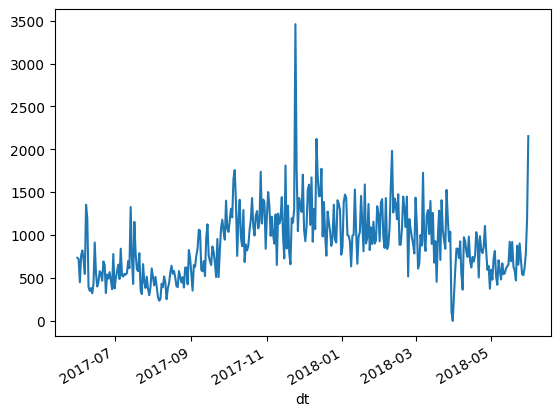

In [25]:
costs.groupby('dt')['costs'].sum().plot()

<AxesSubplot:xlabel='Source Id'>

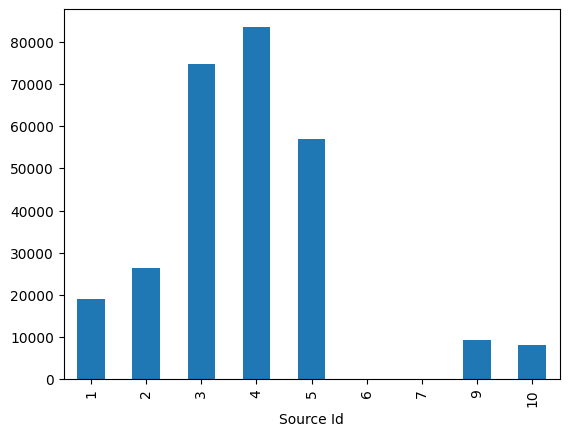

In [26]:
visits.groupby('Source Id')['Uid'].nunique().plot(kind='bar')

<AxesSubplot:xlabel='Buy Ts'>

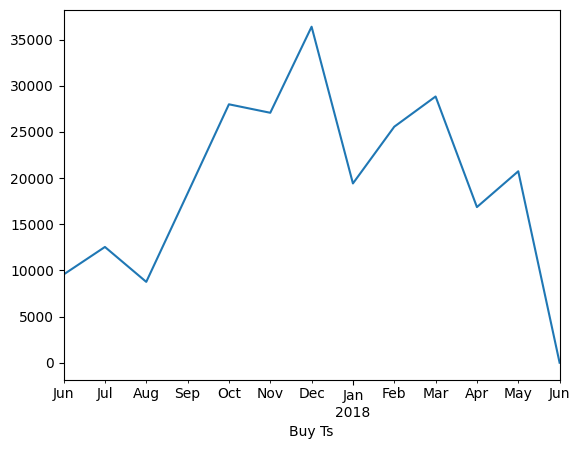

In [27]:
orders.set_index('Buy Ts')['Revenue'].resample('M').sum().plot()